Name: Sania   
CMS ID: 023-24-0277   
Section: H   
GitHub Profile: https://github.com/saniamirani   
Kaggle Profile: https://www.kaggle.com/saniam58   
Dataset: House Prices: Advanced Regression Techniques   
Dataset Source: Kaggle

In [2]:
#task 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

display(train.head())
display(train.describe())
train.info()


Train shape: (1460, 81)
Test shape: (1459, 80)
Sample submission shape: (1459, 2)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [3]:
#task 2
target = "SalePrice"
numeric_features = [
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "FullBath"
]
categorical_features = [
    "Neighborhood",
    "HouseStyle",
    "KitchenQual"
]

features = numeric_features + categorical_features

print("Dependent variable:", target)
print("\nNumerical independent variables:")
print(numeric_features)
print("\nCategorical independent variables:")
print(categorical_features)


Dependent variable: SalePrice

Numerical independent variables:
['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath']

Categorical independent variables:
['Neighborhood', 'HouseStyle', 'KitchenQual']


#task 3   
SalePrice contains numerical house prices rather than discrete class labels. The purpose is to estimate a continuous value, so this is a regression task.

In [25]:
#task 4,5
X = train[features]
y = train[target]
X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)
X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)
print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
display(X.head())


Shape: (1460, 40)
Missing values: 0


,GrLivArea,OverallQual,TotalBsmtSF,GarageCars,YearBuilt,FullBath,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,...,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA
0,1710,7,856,2,2003,2,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,1262,6,1262,2,1976,2,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True
2,1786,7,920,2,2001,2,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
3,1717,7,756,3,1915,1,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
4,2198,8,1145,3,2000,2,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False


Categorical variables are one-hot encoded because their categories do not have a natural numerical order.

In [27]:
#task 6
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1168, 40)
X_test : (292, 40)
y_train: (1168,)
y_test : (292,)


In [16]:
#task 7
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")


Linear Regression model trained successfully.


In [28]:
#task8
y_pred = model.predict(X_test)

prediction_table = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})
display(prediction_table.head(10))

,Actual Price,Predicted Price
0,154500,138195.052756
1,325000,328867.743208
2,115000,113143.942598
3,159000,172384.113462
4,315500,316652.531867
5,75500,64623.276194
6,311500,230810.629290
7,146000,146120.202484
8,84500,64259.346233
9,135500,116896.236387


The table compares actual house prices with prices predicted by the Linear Regression model for 10 test houses. Differences between these values represent prediction errors.

In [23]:
#task 9
coef_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coef_table["Interpretation"] = coef_table["Coefficient"].apply(
    lambda c: f"For a one-unit increase in this encoded feature, predicted SalePrice changes by approximately {c:,.2f}, holding other features constant."
)

print("Intercept:", model.intercept_)
display(coef_table.sort_values("Coefficient", key=abs, ascending=False))


Intercept: -357304.02630226477


,Feature,Coefficient,Interpretation
20,Neighborhood_NoRidge,77320.013643,For a one-unit increase in this encoded featur...
27,Neighborhood_StoneBr,66269.947522,For a one-unit increase in this encoded featur...
21,Neighborhood_NridgHt,58103.677721,For a one-unit increase in this encoded featur...
37,KitchenQual_Fa,-53370.042665,For a one-unit increase in this encoded featur...
39,KitchenQual_TA,-50968.582538,For a one-unit increase in this encoded featur...
29,Neighborhood_Veenker,49087.816978,For a one-unit increase in this encoded featur...
38,KitchenQual_Gd,-43969.771278,For a one-unit increase in this encoded featur...
11,Neighborhood_Crawfor,43296.886821,For a one-unit increase in this encoded featur...
9,Neighborhood_ClearCr,39138.851163,For a one-unit increase in this encoded featur...
28,Neighborhood_Timber,34205.787675,For a one-unit increase in this encoded featur...


#task 10   
Intercept interpretation

The intercept is the predicted price when every model feature is zero. Because the selected features and one-hot encoded categories do not represent a realistic house when all are zero, the intercept does not have a strong direct real-world interpretation.

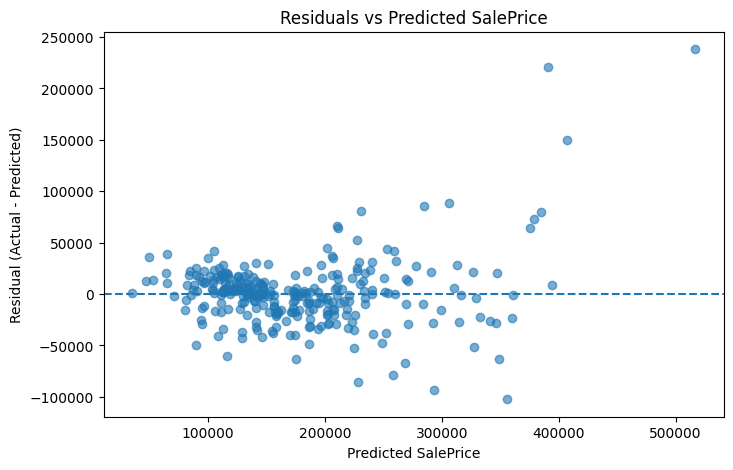

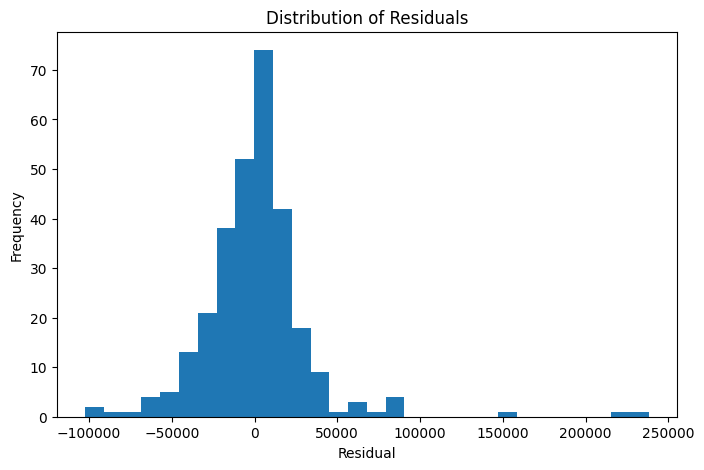

In [29]:
#task 11
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted SalePrice")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted SalePrice")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()


The residuals are not completely randomly scattered; they are mostly around zero, but the spread becomes larger as predicted price increases, with several clear outliers.
This suggests a visible pattern, meaning the model’s prediction errors are not equally spread across all price levels.

In [30]:
#task 12   
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

test_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Test Value": [mae, mse, rmse, r2]
})

display(test_metrics)


,Metric,Test Value
0,MAE,2.064998e+04
1,MSE,1.131594e+09
2,RMSE,3.363917e+04
3,R²,8.524712e-01


#task 13   
- **MAE** shows the average absolute prediction error in price units.
- **MSE** gives greater weight to larger errors because errors are squared.
- **RMSE** is in the same units as house price and penalizes large errors.
- **R²** indicates how much variation in `SalePrice` is explained by the model.

For a non-technical stakeholder, **MAE** is often easier to understand because it directly represents the average absolute prediction error in price units.

In [33]:
#task 14    
train_pred = model.predict(X_train)
train_metrics = {
    "MAE": mean_absolute_error(y_train, train_pred),
    "MSE": mean_squared_error(y_train, train_pred),
    "RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
    "R²": r2_score(y_train, train_pred)
}
test_metrics_dict = {
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "R²": r2
}

comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Training": [train_metrics[m] for m in ["MAE", "MSE", "RMSE", "R²"]],
    "Testing": [test_metrics_dict[m] for m in ["MAE", "MSE", "RMSE", "R²"]]
})
display(comparison)

,Metric,Training,Testing
0,MAE,2.068552e+04,2.064998e+04
1,MSE,1.070490e+09,1.131594e+09
2,RMSE,3.271834e+04,3.363917e+04
3,R²,8.205246e-01,8.524712e-01


#task 15   
There is no large gap between training and testing performance: MAE and RMSE are very close, and testing R² (0.8525) is even slightly higher than training R² (0.8205).
A large train–test gap would suggest overfitting, where the model performs much better on training data than unseen data.
Here, the small difference suggests reasonable generalization and no strong evidence of overfitting.

In [37]:
#task 16
top_features = coef_table.reindex(
    coef_table["Coefficient"].abs().sort_values(ascending=False).index
).head(3)

display(top_features[["Feature", "Coefficient"]])


,Feature,Coefficient
20,Neighborhood_NoRidge,77320.013643
27,Neighborhood_StoneBr,66269.947522
21,Neighborhood_NridgHt,58103.677721


These neighborhood categories have the largest coefficient magnitudes in your model, but this does not automatically mean they are the most important features, because coefficient sizes depend on feature scaling and encoding.

In [38]:
#task 17
print(f"Test MAE:  {mae:,.2f}")
print(f"Test MSE:  {mse:,.2f}")
print(f"Test RMSE: {rmse:,.2f}")
print(f"Test R²:   {r2:.4f}")

best_abs = coef_table.loc[coef_table["Coefficient"].abs().idxmax()]

print("\nStrongest coefficient by absolute magnitude:")
print(best_abs["Feature"], "=", best_abs["Coefficient"])


Test MAE:  20,649.98
Test MSE:  1,131,593,807.91
Test RMSE: 33,639.17
Test R²:   0.8525

Strongest coefficient by absolute magnitude:
Neighborhood_NoRidge = 77320.01364331011


Final Interpretation

The model predicts house prices reasonably well, with a test R² of 0.8525 and an RMSE of about 33,639.
MAE is the most useful metric for a general stakeholder because it shows the average prediction error directly in price units, about 20,650.
The feature with the strongest coefficient is Neighborhood_NoRidge, with a coefficient of approximately 77,320.
However, coefficient magnitude alone does not prove overall feature importance because the features have different scales and categorical variables are one-hot encoded.
A limitation of Linear Regression is that it may not capture complex nonlinear relationships and interactions between house features.
As a next step, I would try more flexible regression models and additional feature engineering to see whether prediction performance improves.

In [43]:
#task 18
X_test_kaggle = test[features].copy()
X_test_kaggle = pd.get_dummies(
    X_test_kaggle,
    columns=categorical_features,
    drop_first=True
)

X_test_kaggle = X_test_kaggle.reindex(columns=X.columns, fill_value=0)
X_test_kaggle = X_test_kaggle.fillna(X.median())

kaggle_predictions = model.predict(X_test_kaggle)

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": kaggle_predictions
})

submission = submission[["Id", "SalePrice"]]

submission.to_csv("Kaggle_House_Price_Prediction_submission.csv", index=False)

print("Kaggle_House_Price_Prediction_submission.csv created successfully.")
print("Shape:", submission.shape)
display(submission.head())


Kaggle_House_Price_Prediction_submission.csv created successfully.
Shape: (1459, 2)


,Id,SalePrice
0,1461,110811.113577
1,1462,160231.021748
2,1463,162748.837066
3,1464,182073.730692
4,1465,254408.665129


#task 19   
It was exciting to see my model receive a real Kaggle score and rank among thousands of submissions. It gave me practical experience in seeing how a machine-learning model performs on unseen real-world data.

In [45]:
kaggle_public_score = "0.16955"
kaggle_rank = "2790"

print("Kaggle Public Score:", kaggle_public_score)
print("Kaggle Rank:", kaggle_rank)


Kaggle Public Score: 0.16955
Kaggle Rank: 2790
